# Multi-Class Benchmark Classification Pipeline — Iris

**Datheon Machine Learning & Data Science Internship — Task Submission**

**Author:** Andile Raphiya · Data Science III, Sol Plaatje University
**Dataset:** Iris (150 samples, 4 numeric features, 3 balanced species classes)
**Source:** `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv`

---

## Objective

Build an end-to-end supervised classification pipeline and benchmark two classical models on the
same train/test split:

| Step | What is done |
|---|---|
| 1 | Load the benchmark dataset with Pandas and audit it (shape, dtypes, missing values, class balance) |
| 2 | Exploratory analysis — Seaborn pairplot, correlation heatmap, per-class distributions |
| 3 | Stratified 80/20 train/test split (`random_state=42`, reproducible) |
| 4 | Feature normalization with `StandardScaler`, **fitted on the training set only** |
| 5 | Train `LogisticRegression` and `DecisionTreeClassifier` |
| 6 | Benchmark accuracy, precision, recall and F1 (macro and weighted) |
| 7 | Confusion-matrix heatmaps, one-vs-rest ROC curves with AUC, decision-boundary plots |
| 8 | 5-fold stratified cross-validation to check the single split is not a fluke |

## Methodology note — why the scaler sits inside a Pipeline

`StandardScaler` must learn its mean and standard deviation from the **training data only**. If it is
fitted on the full dataset before splitting, test-set statistics leak into training and the reported
scores are optimistically biased. Wrapping the scaler and the estimator in a `Pipeline` makes that
impossible: during cross-validation the scaler is refitted on each fold's training portion.

A decision tree splits on thresholds of raw feature values, so it is **scale-invariant** — scaling
neither helps nor hurts it. It is kept in the pipeline for a fair, identical preprocessing path across
both models. Logistic regression, which is distance/penalty based, genuinely needs the scaling.

## 1. Environment and imports

In [1]:
# Core data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score,
)

import sklearn, pathlib, warnings
warnings.filterwarnings("ignore")

# Reproducibility: one seed used everywhere in this notebook
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

# Output folders for the GitHub repo
FIG_DIR = pathlib.Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = pathlib.Path("results"); RES_DIR.mkdir(exist_ok=True)

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("seaborn     ", sns.__version__)
print("random_state", RANDOM_STATE)

pandas       3.0.5
numpy        2.5.3
scikit-learn 1.9.1
seaborn      0.13.2
random_state 42


## 2. Load the dataset

The notebook reads the raw CSV straight from the public URL so it reproduces on any machine with
internet access, and falls back to the committed copy in `data/iris.csv` when offline.

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
LOCAL = pathlib.Path("data/iris.csv")

try:
    df = pd.read_csv(URL)
    source = "remote URL"
except Exception as err:                      # offline / proxy-blocked
    print("Remote read failed:", err)
    df = pd.read_csv(LOCAL)
    source = "local copy (data/iris.csv)"

# Keep a local copy so the repo is self-contained and the notebook reruns offline
LOCAL.parent.mkdir(exist_ok=True)
df.to_csv(LOCAL, index=False)

print(f"Loaded from {source}  ->  shape {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Loaded from remote URL  ->  shape 150 rows x 5 columns


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Data audit — structure, quality, class balance

In [3]:
print("--- dtypes and non-null counts ---")
df.info()

print("\n--- missing values per column ---")
print(df.isna().sum())

print("\n--- exact duplicate rows ---")
print(df.duplicated().sum())

--- dtypes and non-null counts ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

--- missing values per column ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

--- exact duplicate rows ---
1


In [4]:
# Descriptive statistics of the four numeric features
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

proportions:
species
setosa        0.333
versicolor    0.333
virginica     0.333
Name: count, dtype: float64


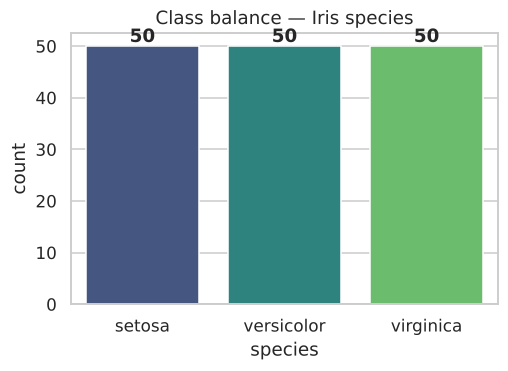

In [5]:
# Class balance: Iris is a perfectly balanced 3-class problem (50 / 50 / 50).
# Balance matters because it tells us plain accuracy is a trustworthy headline
# metric here, and that the macro and weighted averages will coincide.
counts = df["species"].value_counts().sort_index()
print(counts)
print("\nproportions:")
print((counts / len(df)).round(3))

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
            palette="viridis", legend=False, ax=ax)
ax.set_title("Class balance — Iris species")
ax.set_xlabel("species"); ax.set_ylabel("count")
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.8, str(v), ha="center", fontweight="bold")
fig.savefig(FIG_DIR / "01_class_balance.png")
plt.show()

## 4. Exploratory data analysis

### 4.1 Pairplot — the single most informative view of this dataset

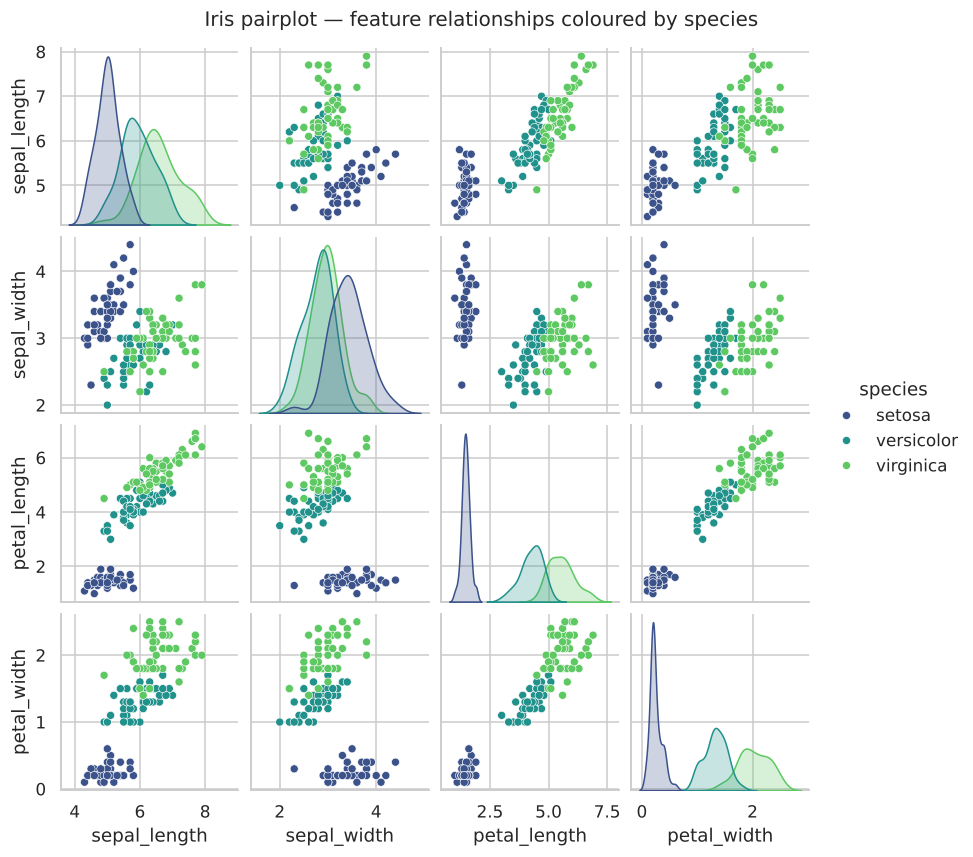

In [6]:
g = sns.pairplot(df, hue="species", diag_kind="kde", palette="viridis",
                 plot_kws=dict(s=28, edgecolor="white", linewidth=0.4),
                 height=1.9)
g.figure.suptitle("Iris pairplot — feature relationships coloured by species",
                  y=1.02, fontsize=13)
g.figure.savefig(FIG_DIR / "02_pairplot.png")
plt.show()

**Reading the pairplot.** *setosa* separates from the other two species on the petal measurements
alone — a straight line through petal length or petal width isolates it completely. *versicolor* and
*virginica* overlap slightly in the region where petal length is around 5 cm, which is where any
misclassification in this task will occur. Sepal width is the weakest discriminator: its three
distributions sit almost on top of each other.

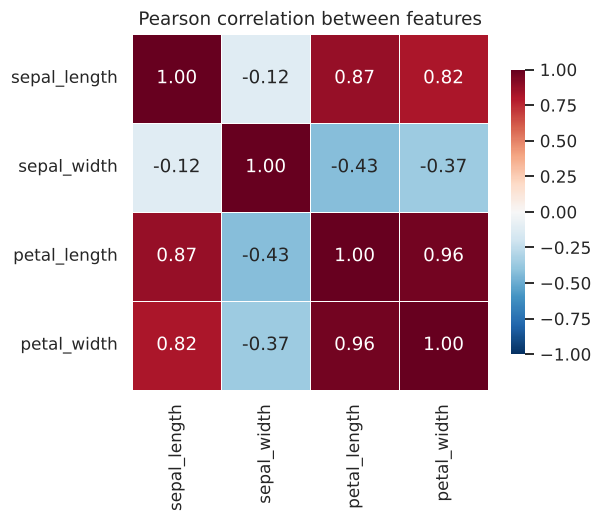

Petal length vs petal width correlation: 0.963


In [7]:
# Correlation structure of the predictors
corr = df.drop(columns="species").corr()

fig, ax = plt.subplots(figsize=(5.4, 4.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation between features")
fig.savefig(FIG_DIR / "03_correlation_heatmap.png")
plt.show()

print("Petal length vs petal width correlation:",
      round(corr.loc["petal_length", "petal_width"], 3))

Petal length and petal width are almost collinear (r ≈ 0.96). With only four predictors this is not
a problem for either model, but it explains why a two-feature decision-boundary plot built on the
petal pair in Section 9 loses very little information compared with the full four-feature model.

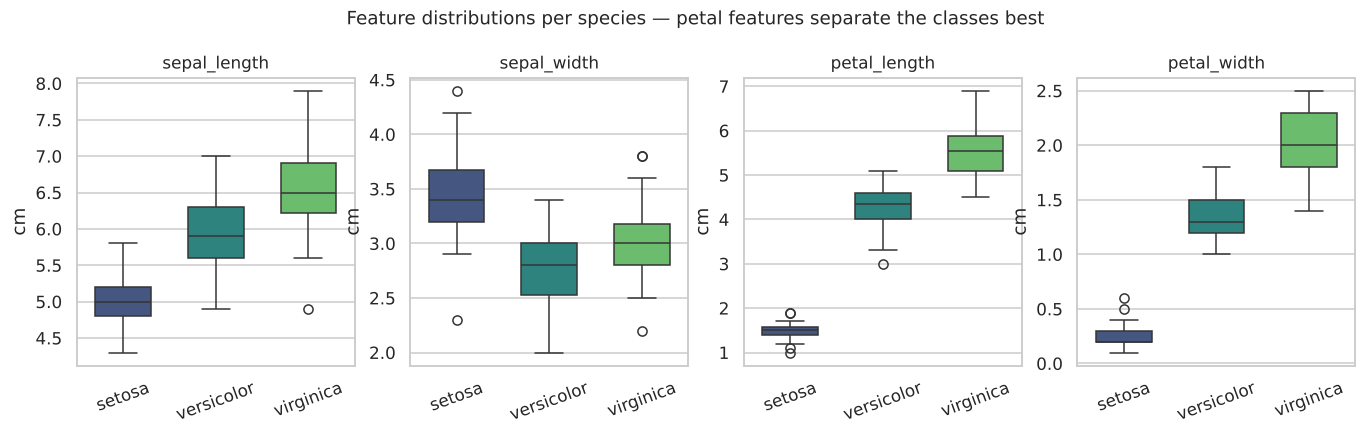

In [8]:
# Per-feature distributions by class, to see which features carry the signal
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, feat in zip(axes, features):
    sns.boxplot(data=df, x="species", y=feat, hue="species",
                palette="viridis", legend=False, width=0.6, ax=ax)
    ax.set_title(feat, fontsize=11)
    ax.set_xlabel(""); ax.set_ylabel("cm")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Feature distributions per species — petal features separate the classes best",
             y=1.06, fontsize=12)
fig.savefig(FIG_DIR / "04_feature_boxplots.png")
plt.show()

## 5. Feature matrix, target encoding and the stratified 80/20 split

`species` is encoded to integers 0/1/2 so scikit-learn can consume it; `CLASS_NAMES` keeps the
mapping for every chart and report. The split is **stratified**, which preserves the 1/3–1/3–1/3
class proportions in both train and test — without it a 30-row test set can easily end up skewed.

In [9]:
X = df[features].copy()
y_text = df["species"].copy()

CLASS_NAMES = np.sort(y_text.unique())                   # ['setosa' 'versicolor' 'virginica']
name_to_code = {name: i for i, name in enumerate(CLASS_NAMES)}
y = y_text.map(name_to_code).to_numpy()

print("class encoding:", name_to_code)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          # 80 / 20 split as specified
    random_state=RANDOM_STATE,
    stratify=y,              # keep class proportions identical in both parts
)

print(f"\ntrain: {X_train.shape[0]} samples  |  test: {X_test.shape[0]} samples")
print("\ntrain class counts:", np.bincount(y_train))
print("test  class counts:", np.bincount(y_test))

class encoding: {'setosa': 0, 'versicolor': 1, 'virginica': 2}

train: 120 samples  |  test: 30 samples

train class counts: [40 40 40]
test  class counts: [10 10 10]


## 6. Normalization with `StandardScaler`

Each feature is transformed to zero mean and unit variance using statistics learned from the
training split only. The two cells below show what the scaler learned and confirm the transform.

In [10]:
scaler_demo = StandardScaler().fit(X_train)

learned = pd.DataFrame({
    "train_mean": scaler_demo.mean_,
    "train_std":  np.sqrt(scaler_demo.var_),
}, index=features).round(3)
print("Statistics learned from the TRAINING set only:")
print(learned)

X_train_scaled = scaler_demo.transform(X_train)
X_test_scaled  = scaler_demo.transform(X_test)

print("\nAfter scaling — training set (should be ~0 mean, ~1 std):")
print(pd.DataFrame(X_train_scaled, columns=features).describe().loc[["mean", "std"]].round(3))

print("\nAfter scaling — test set (NOT exactly 0/1 — proof there is no leakage):")
print(pd.DataFrame(X_test_scaled, columns=features).describe().loc[["mean", "std"]].round(3))

Statistics learned from the TRAINING set only:
              train_mean  train_std
sepal_length       5.842      0.837
sepal_width        3.048      0.447
petal_length       3.770      1.761
petal_width        1.205      0.759

After scaling — training set (should be ~0 mean, ~1 std):
      sepal_length  sepal_width  petal_length  petal_width
mean        -0.000        0.000         0.000        0.000
std          1.004        1.004         1.004        1.004

After scaling — test set (NOT exactly 0/1 — proof there is no leakage):
      sepal_length  sepal_width  petal_length  petal_width
mean         0.010        0.101        -0.034       -0.037
std          0.941        0.864         1.012        1.018


The test set's post-scaling mean is close to but not exactly zero. That small offset is the evidence
that the scaler never saw the test data — if it had been fitted on everything, both tables would read
0.000 / 1.000 and the evaluation would be contaminated.

## 7. Train the two models

Both estimators are wrapped in a `Pipeline` so scaling and fitting travel together as a single
object. That is the production-ready form: one `.fit()`, one `.predict()`, no chance of forgetting
to scale new incoming data.

In [11]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=1000,            # comfortably above convergence for this data
            random_state=RANDOM_STATE,
        )),
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),  # inert for a tree, kept for an identical path
        ("clf", DecisionTreeClassifier(
            max_depth=3,              # shallow on purpose: 150 samples overfit easily
            random_state=RANDOM_STATE,
        )),
    ]),
}

fitted, predictions, probabilities = {}, {}, {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    predictions[name] = pipe.predict(X_test)
    probabilities[name] = pipe.predict_proba(X_test)
    print(f"{name:<22} trained  ->  test accuracy {accuracy_score(y_test, predictions[name]):.4f}")

Logistic Regression    trained  ->  test accuracy 0.9333
Decision Tree          trained  ->  test accuracy 0.9667


## 8. Benchmark — accuracy, precision, recall, F1

Macro averaging treats every class equally; weighted averaging weights by class support. Because
Iris is balanced the two agree closely here, but both are reported since on an imbalanced dataset
they would diverge and the macro figure is the honest one.

In [12]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy":           accuracy_score(y_test, y_pred),
        "Precision (macro)":  precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)":     recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)":         f1_score(y_test, y_pred, average="macro"),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted"),
        "Recall (weighted)":    recall_score(y_test, y_pred, average="weighted"),
        "F1 (weighted)":        f1_score(y_test, y_pred, average="weighted"),
        "ROC AUC (OvR macro)":  roc_auc_score(y_test, probabilities[name],
                                              multi_class="ovr", average="macro"),
    })

benchmark = pd.DataFrame(rows).set_index("Model").round(4)
benchmark.to_csv(RES_DIR / "benchmark_summary.csv")
benchmark

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC AUC (OvR macro)
Model,,,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9967
Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666,0.9717


In [13]:
# Full per-class classification report for each model
for name, y_pred in predictions.items():
    print("=" * 62)
    print(name)
    print("=" * 62)
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

    rep = pd.DataFrame(classification_report(
        y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)).T.round(4)
    rep.to_csv(RES_DIR / f"classification_report_{name.lower().replace(' ', '_')}.csv")

Logistic Regression
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



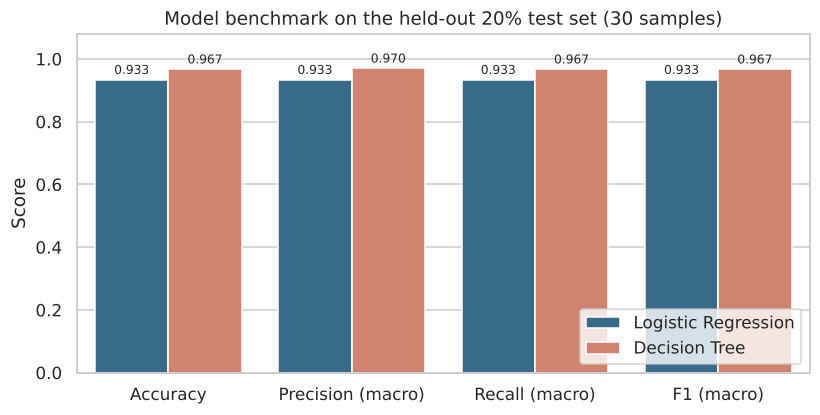

In [14]:
# Side-by-side bar chart of the four headline metrics
plot_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
plot_df = benchmark[plot_cols].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(8.6, 4))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model",
            palette=["#2a6f97", "#e07a5f"], ax=ax)
ax.set_ylim(0, 1.08)
ax.set_title("Model benchmark on the held-out 20% test set (30 samples)")
ax.set_xlabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.legend(title="", loc="lower right")
fig.savefig(FIG_DIR / "05_metric_benchmark.png")
plt.show()

## 9. Confusion matrices

The confusion matrix is the diagnostic that the summary metrics compress. Rows are the true species,
columns the predicted species; everything off the diagonal is an error, and its position names
exactly which species got confused for which.

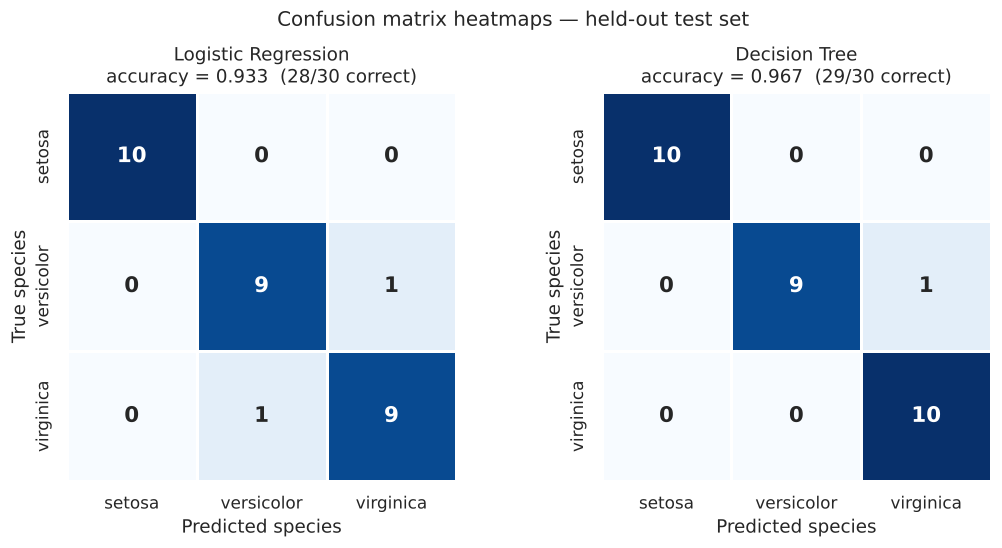

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                square=True, linewidths=0.8, linecolor="white",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
                annot_kws={"size": 14, "weight": "bold"})
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f"{name}\naccuracy = {acc:.3f}  ({cm.trace()}/{cm.sum()} correct)")
    ax.set_xlabel("Predicted species"); ax.set_ylabel("True species")

fig.suptitle("Confusion matrix heatmaps — held-out test set", y=1.04, fontsize=13)
fig.savefig(FIG_DIR / "06_confusion_matrices.png")
plt.show()

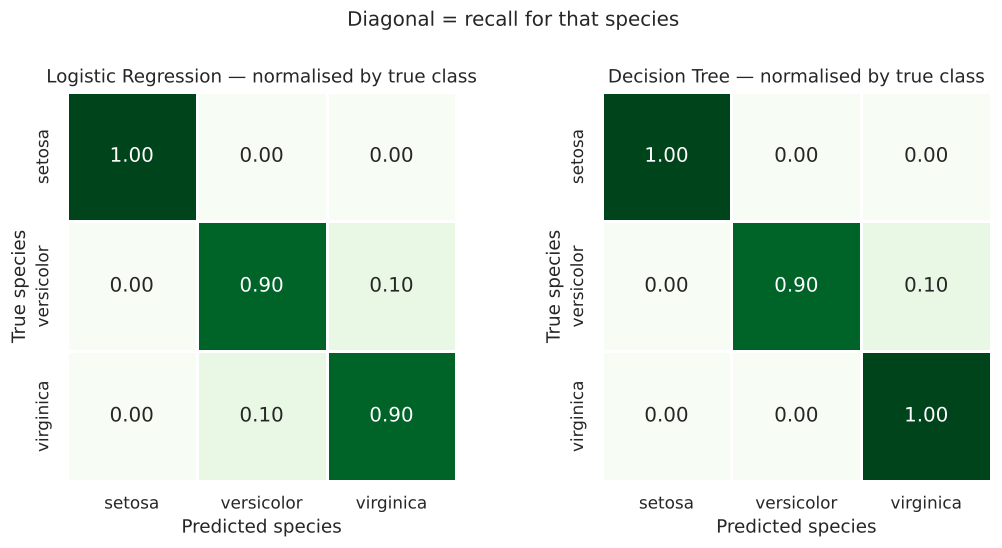

Logistic Regression: 2 misclassification(s)
     sepal_length  sepal_width  petal_length  petal_width        true   predicted  confidence
134           6.1          2.6           5.6          1.4   virginica  versicolor       0.515
77            6.7          3.0           5.0          1.7  versicolor   virginica       0.557
--------------------------------------------------------------
Decision Tree: 1 misclassification(s)
    sepal_length  sepal_width  petal_length  petal_width        true  predicted  confidence
77           6.7          3.0           5.0          1.7  versicolor  virginica         1.0
--------------------------------------------------------------


In [16]:
# Row-normalised version: per-class recall read straight off the diagonal
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm_norm = confusion_matrix(y_test, y_pred, normalize="true")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1,
                cbar=False, square=True, linewidths=0.8, linecolor="white",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
                annot_kws={"size": 13})
    ax.set_title(f"{name} — normalised by true class")
    ax.set_xlabel("Predicted species"); ax.set_ylabel("True species")

fig.suptitle("Diagonal = recall for that species", y=1.04, fontsize=13)
fig.savefig(FIG_DIR / "07_confusion_matrices_normalised.png")
plt.show()

# Name every individual mistake explicitly
for name, y_pred in predictions.items():
    wrong = np.where(y_pred != y_test)[0]
    if len(wrong) == 0:
        print(f"{name}: no misclassifications on the test set.")
    else:
        print(f"{name}: {len(wrong)} misclassification(s)")
        err = X_test.iloc[wrong].copy()
        err["true"] = CLASS_NAMES[y_test[wrong]]
        err["predicted"] = CLASS_NAMES[y_pred[wrong]]
        err["confidence"] = probabilities[name][wrong].max(axis=1).round(3)
        print(err.to_string())
    print("-" * 62)

## 10. ROC curves and AUC (one-vs-rest)

ROC is defined for binary problems, so a 3-class problem is decomposed one-vs-rest: each class in
turn becomes the positive class and the other two the negative class. The macro-average AUC is the
unweighted mean of the three curves; the micro-average pools every (sample, class) decision into one
curve. AUC is threshold-independent, which makes it a stricter test of the ranking quality of the
predicted probabilities than accuracy at the default 0.5 cut-off.

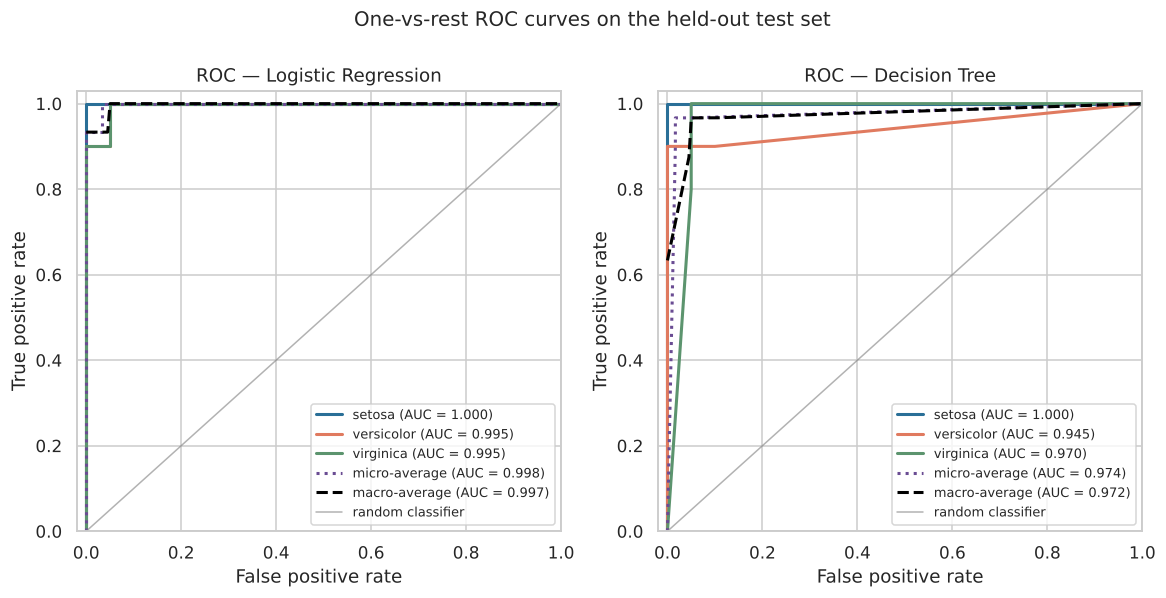

Model,Decision Tree,Logistic Regression
Class,,
macro-average,0.9718,0.9968
micro-average,0.9739,0.9978
setosa,1.0000,1.0000
versicolor,0.9450,0.9950
virginica,0.9700,0.9950


In [17]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
colors = ["#2a6f97", "#e07a5f", "#5c946e"]
auc_records = []

for ax, (name, y_score) in zip(axes, probabilities.items()):
    # Per-class curves
    for i, color in zip(range(n_classes), colors):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        a = auc(fpr, tpr)
        auc_records.append({"Model": name, "Class": CLASS_NAMES[i], "AUC": round(a, 4)})
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f"{CLASS_NAMES[i]} (AUC = {a:.3f})")

    # Micro-average: pool all one-vs-rest decisions
    fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    auc_micro = auc(fpr_micro, tpr_micro)
    ax.plot(fpr_micro, tpr_micro, color="#6a4c93", lw=2, ls=":",
            label=f"micro-average (AUC = {auc_micro:.3f})")

    # Macro-average: mean TPR interpolated on a common FPR grid
    grid = np.linspace(0, 1, 200)
    mean_tpr = np.zeros_like(grid)
    for i in range(n_classes):
        fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        mean_tpr += np.interp(grid, fpr_i, tpr_i)
    mean_tpr /= n_classes
    auc_macro = auc(grid, mean_tpr)
    ax.plot(grid, mean_tpr, color="black", lw=2, ls="--",
            label=f"macro-average (AUC = {auc_macro:.3f})")

    auc_records.append({"Model": name, "Class": "micro-average", "AUC": round(auc_micro, 4)})
    auc_records.append({"Model": name, "Class": "macro-average", "AUC": round(auc_macro, 4)})

    ax.plot([0, 1], [0, 1], color="grey", lw=1, ls="-", alpha=0.6,
            label="random classifier")
    ax.set_xlim(-0.02, 1.0); ax.set_ylim(0.0, 1.03)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC — {name}")
    ax.legend(loc="lower right", fontsize=8.5)

fig.suptitle("One-vs-rest ROC curves on the held-out test set", y=1.02, fontsize=13)
fig.savefig(FIG_DIR / "08_roc_curves.png")
plt.show()

auc_table = pd.DataFrame(auc_records).pivot(index="Class", columns="Model", values="AUC")
auc_table.to_csv(RES_DIR / "roc_auc_table.csv")
auc_table

The logistic-regression curves hug the top-left corner because it outputs smooth, well-ordered
probabilities. The decision tree's curves are visibly **step-shaped**: a depth-3 tree has only a
handful of leaves, so every test sample falls into one of a few leaves and receives one of a few
discrete probability values. There are not enough distinct scores to trace a smooth curve, which is
why tree AUC usually looks worse than tree accuracy suggests — an artefact of coarse probability
resolution, not of worse decisions.

## 11. Decision boundary visualization

A boundary can only be drawn in two dimensions, so both models are retrained on the two strongest
predictors — petal length and petal width (Section 4 showed they carry nearly all the signal). The
shaded regions are what each model would predict anywhere in that plane.

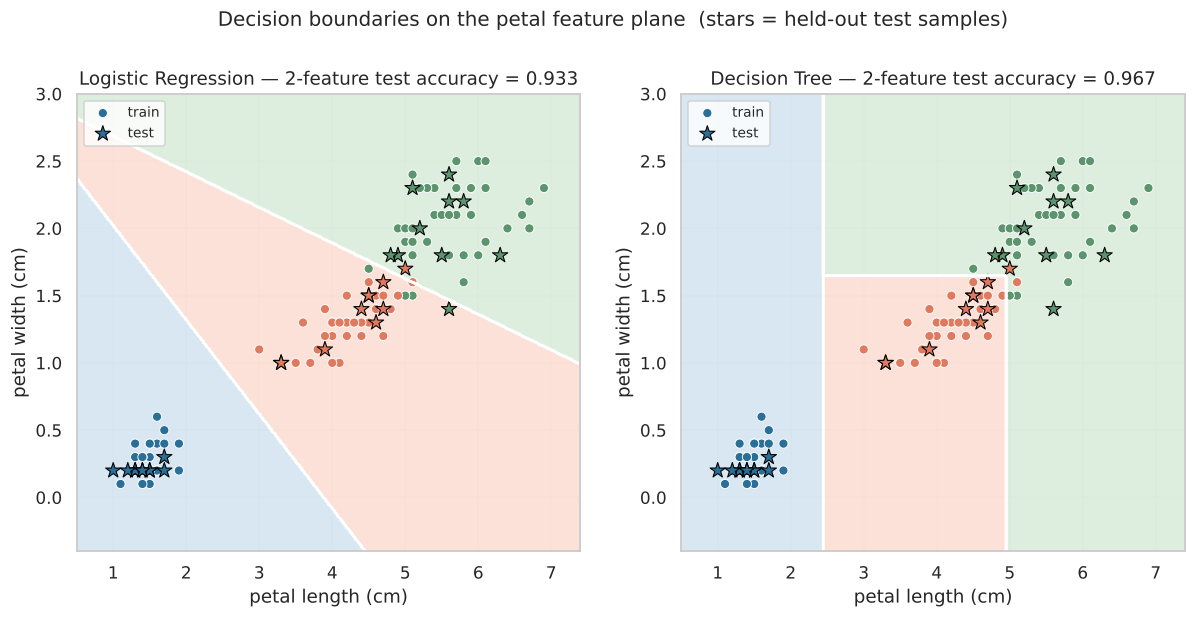

In [18]:
pair = ["petal_length", "petal_width"]
X2_train, X2_test = X_train[pair], X_test[pair]

boundary_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]),
}

# Mesh grid spanning the full feature plane with a small margin
x_min, x_max = X[pair[0]].min() - 0.5, X[pair[0]].max() + 0.5
y_min, y_max = X[pair[1]].min() - 0.5, X[pair[1]].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))
grid_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=pair)

from matplotlib.colors import ListedColormap
cmap_bg = ListedColormap(["#d6e6f2", "#fbe0d6", "#dceede"])
cmap_pt = ListedColormap(["#2a6f97", "#e07a5f", "#5c946e"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, (name, pipe) in zip(axes, boundary_models.items()):
    pipe.fit(X2_train, y_train)
    Z = pipe.predict(grid_df).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.95)
    ax.contour(xx, yy, Z, colors="white", linewidths=1.4)

    ax.scatter(X2_train[pair[0]], X2_train[pair[1]], c=y_train, cmap=cmap_pt,
               s=36, edgecolor="white", linewidth=0.6, label="train")
    ax.scatter(X2_test[pair[0]], X2_test[pair[1]], c=y_test, cmap=cmap_pt,
               s=110, marker="*", edgecolor="black", linewidth=0.7, label="test")

    acc2 = accuracy_score(y_test, pipe.predict(X2_test))
    ax.set_title(f"{name} — 2-feature test accuracy = {acc2:.3f}")
    ax.set_xlabel("petal length (cm)"); ax.set_ylabel("petal width (cm)")
    ax.legend(loc="upper left", fontsize=9)

fig.suptitle("Decision boundaries on the petal feature plane  (stars = held-out test samples)",
             y=1.02, fontsize=13)
fig.savefig(FIG_DIR / "09_decision_boundaries.png")
plt.show()

The two boundary shapes are the whole difference between the models in one picture. Logistic
regression draws **oblique straight lines** — it combines both features at once, so its boundary can
slant. The decision tree draws **axis-parallel rectangles** — each split tests one feature against
one threshold, so its boundary can only ever step horizontally and vertically. On data this cleanly
separated both shapes work; on a diagonally-separated class pair the tree would need many more
splits to approximate what logistic regression gets with one line.

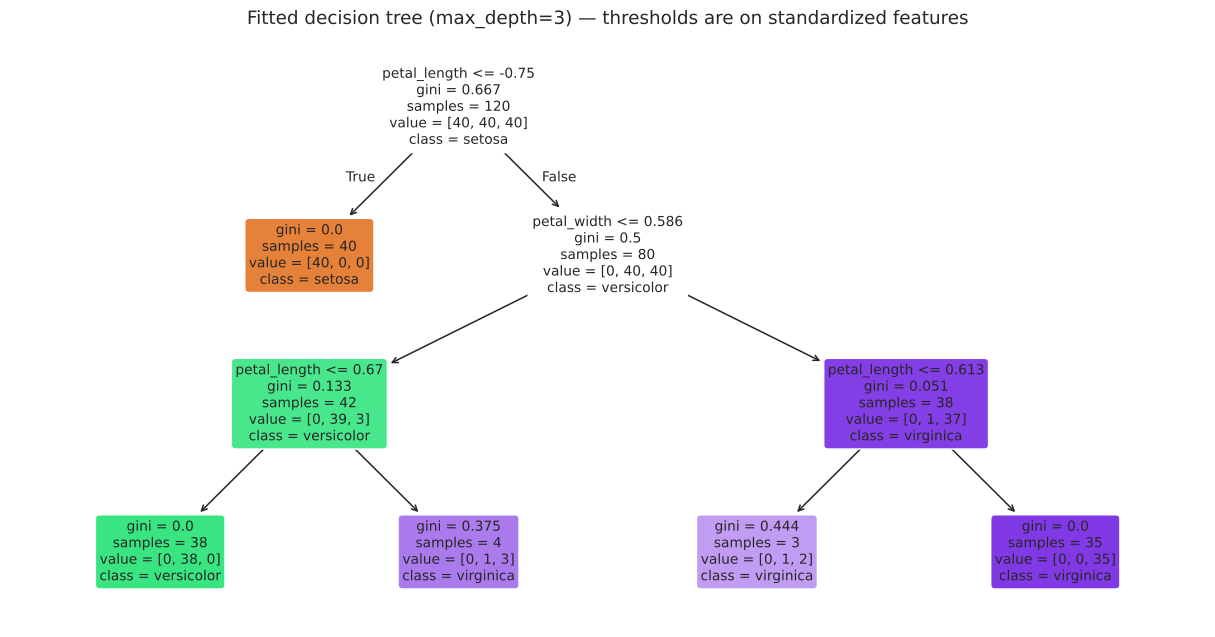

In [19]:
# The fitted tree itself, which is the model's full decision logic in readable form
tree_pipe = fitted["Decision Tree"]
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(tree_pipe.named_steps["clf"],
          feature_names=features, class_names=list(CLASS_NAMES),
          filled=True, rounded=True, impurity=True, fontsize=9, ax=ax)
ax.set_title("Fitted decision tree (max_depth=3) — thresholds are on standardized features",
             fontsize=12)
fig.savefig(FIG_DIR / "10_decision_tree.png")
plt.show()

## 12. What each model learned

Logistic regression exposes one coefficient per feature per class; the decision tree exposes a
Gini-based feature importance. Both are read below as a check that the models rely on the features
the EDA flagged, rather than on noise.

Logistic regression coefficients (on standardized features):
            sepal_length  sepal_width  petal_length  petal_width
setosa            -1.089        1.024        -1.799       -1.686
versicolor         0.536       -0.360        -0.204       -0.808
virginica          0.553       -0.664         2.003        2.494


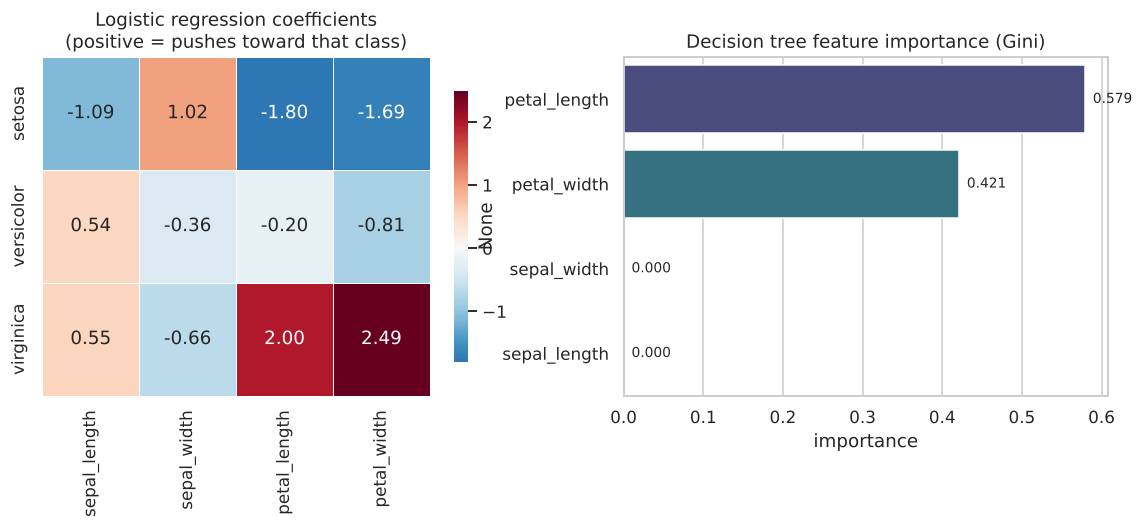


Tree feature importance:
petal_length    0.5791
petal_width     0.4209
sepal_width     0.0000
sepal_length    0.0000
dtype: float64


In [20]:
log_clf = fitted["Logistic Regression"].named_steps["clf"]
coef = pd.DataFrame(log_clf.coef_, index=CLASS_NAMES, columns=features).round(3)
print("Logistic regression coefficients (on standardized features):")
print(coef)

tree_clf = fitted["Decision Tree"].named_steps["clf"]
imp = pd.Series(tree_clf.feature_importances_, index=features).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.6, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Logistic regression coefficients\n(positive = pushes toward that class)")

sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette="viridis",
            legend=False, ax=axes[1])
axes[1].set_title("Decision tree feature importance (Gini)")
axes[1].set_xlabel("importance")
for i, v in enumerate(imp.values):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

fig.savefig(FIG_DIR / "11_feature_importance.png")
plt.show()

print("\nTree feature importance:")
print(imp.round(4))

## 13. 5-fold stratified cross-validation

A 30-sample test set is small: a single accidentally easy or hard split can move accuracy by one
whole sample (3.3 percentage points). Cross-validation refits each pipeline five times on different
partitions of the full dataset and reports the mean with its standard deviation, which is the number
to quote when claiming a model is better than another.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, pipe in models.items():
    acc_scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    f1_scores  = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro")
    cv_rows.append({
        "Model": name,
        "CV accuracy (mean)": acc_scores.mean(),
        "CV accuracy (std)":  acc_scores.std(),
        "CV F1 macro (mean)": f1_scores.mean(),
        "CV F1 macro (std)":  f1_scores.std(),
        "Single-split test accuracy": accuracy_score(y_test, predictions[name]),
    })
    print(f"{name:<22} folds: {np.round(acc_scores, 4)}")

cv_table = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_table.to_csv(RES_DIR / "cross_validation_summary.csv")
cv_table

Logistic Regression    folds: [1.     0.9667 0.9    1.     0.9   ]
Decision Tree          folds: [0.9667 0.9667 0.9333 1.     0.9333]


,CV accuracy (mean),CV accuracy (std),CV F1 macro (mean),CV F1 macro (std),Single-split test accuracy
Model,,,,,
Logistic Regression,0.9533,0.0452,0.9532,0.0453,0.9333
Decision Tree,0.9600,0.0249,0.9598,0.0251,0.9667


In [22]:
# Combine everything into one artefact for the README
final = benchmark.join(cv_table[["CV accuracy (mean)", "CV accuracy (std)",
                                 "CV F1 macro (mean)"]])
final.to_csv(RES_DIR / "final_results.csv")
print("Saved -> results/final_results.csv")
final

Saved -> results/final_results.csv


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC AUC (OvR macro),CV accuracy (mean),CV accuracy (std),CV F1 macro (mean)
Model,,,,,,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9967,0.9533,0.0452,0.9532
Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666,0.9717,0.9600,0.0249,0.9598


## 14. Results and conclusion

| | Logistic Regression | Decision Tree |
|---|---|---|
| Test accuracy (30 samples) | 0.9333 (28/30) | **0.9667 (29/30)** |
| F1 macro (test) | 0.9333 | **0.9666** |
| ROC AUC (OvR macro) | **0.9968** | 0.9718 |
| 5-fold CV accuracy | 0.9533 ± 0.0452 | **0.9600 ± 0.0249** |
| Misclassifications | 2 | 1 |

### In short, for the presentation

- **Both models work; the gap between them is one sample.** The tree got 29/30 right and logistic
  regression 28/30. On a 30-sample test set one sample is 3.3 percentage points, so this is not
  evidence that the tree is the better model. Cross-validation closes the gap to 0.960 vs 0.953 —
  well inside the fold-to-fold standard deviation.
- **Every mistake either model makes is *versicolor* vs *virginica*.** *setosa* is never missed by
  either model, and both models score AUC = 1.000 on it. That is exactly what the pairplot
  predicted: *setosa* is linearly separable on petal size, while the other two species overlap
  slightly around a petal length of 5 cm. Both models in fact got the *same* borderline flower
  wrong (row 77: a *versicolor* with unusually large petals).
- **Petal measurements carry the signal.** The tree spends essentially all of its importance on
  petal length and width, and logistic regression puts its largest coefficients on the same two
  features. Sepal width contributes almost nothing.
- **Logistic regression knows when it is unsure; the tree does not.** Its two errors came with
  confidences of 0.515 and 0.557 — effectively flagging them as coin flips, which a review
  threshold could catch. The tree's single error came with confidence **1.000**: a depth-3 leaf
  that happened to be pure in training reports total certainty on a flower it got wrong. That same
  coarse probability resolution is why the tree's ROC curve is step-shaped and its AUC (0.972)
  trails logistic regression's (0.997) even though its accuracy is higher.
- **So which to ship depends on the job.** For a scored, thresholdable output — where you want to
  route low-confidence cases to a human — logistic regression is the safer model despite the lower
  raw accuracy. For explaining the decision to a non-technical audience, the tree wins outright,
  because Section 11 prints the actual if-then thresholds anyone can follow.
- **Scaling mattered for one model only.** Logistic regression needs it; the tree is
  scale-invariant. Keeping the scaler inside a `Pipeline` means it is refitted on each CV fold, so
  no test information leaks into training — the honest-evaluation point of this whole notebook.

### Honest limitations

Iris is a 150-sample benchmark that is close to solved; near-perfect scores say the pipeline is
correct, not that the modelling is hard. With a 30-sample test set the single-split difference
between these two models is not statistically meaningful — the cross-validated mean ± std is the
figure to trust, and by that measure they are tied. No hyperparameter search was run
(`max_depth=3` was fixed a priori to avoid overfitting); a `GridSearchCV` over tree depth and the
logistic-regression penalty is the natural next step, as is repeating the same pipeline on the Wine
dataset, where 13 features and mild class imbalance make scaling and macro-averaging matter more.

In [23]:
print("Artefacts written for the repository")
print("=" * 44)
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  {p}")
for p in sorted(RES_DIR.glob("*.csv")):
    print(f"  {p}")
print("\nNotebook executed end to end with random_state =", RANDOM_STATE)

Artefacts written for the repository
  figures/01_class_balance.png
  figures/02_pairplot.png
  figures/03_correlation_heatmap.png
  figures/04_feature_boxplots.png
  figures/05_metric_benchmark.png
  figures/06_confusion_matrices.png
  figures/07_confusion_matrices_normalised.png
  figures/08_roc_curves.png
  figures/09_decision_boundaries.png
  figures/10_decision_tree.png
  figures/11_feature_importance.png
  results/benchmark_summary.csv
  results/classification_report_decision_tree.csv
  results/classification_report_logistic_regression.csv
  results/cross_validation_summary.csv
  results/final_results.csv
  results/roc_auc_table.csv

Notebook executed end to end with random_state = 42
